In [1]:

# ==========================================
# NIGHTWATCH 2.0 - ENVIRONMENT VERIFICATION
# ==========================================

import sys
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Python Version:", sys.version)
print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

# Check GPU availability
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("\nGPU AVAILABLE:")
    for gpu in gpus:
        print(gpu)
else:
    print("\nNo GPU detected. CPU will be used.")

print("\nTensorFlow Build Info:")
print(tf.sysconfig.get_build_info())

print("\nNightWatch environment verification completed!")


Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow Version: 2.21.0
NumPy Version: 2.4.6

GPU AVAILABLE:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

TensorFlow Build Info:
OrderedDict({'cpu_compiler': 'clang', 'cuda_compute_capabilities': ['sm_60', 'sm_70', 'sm_80', 'sm_89', 'compute_90'], 'cuda_version': '12.5.1', 'cudnn_version': '9', 'is_cuda_build': True, 'is_rocm_build': False, 'is_tensorrt_build': False})

NightWatch environment verification completed!


In [2]:

# ==========================================
# NIGHTWATCH 2.0 - GPU CONFIGURATION
# ==========================================

import tensorflow as tf
import subprocess

# Enable memory growth
gpus = tf.config.list_physical_devices('GPU')

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("GPU Configuration:")

if gpus:
    for gpu in gpus:
        print("Detected:", gpu)

    print("\nGPU Details:")
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )
    print(result.stdout)
else:
    print("No GPU available.")

print("\nGPU setup completed!")


GPU Configuration:
Detected: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

GPU Details:
Wed Nov 18 05:23:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                               

In [1]:

from google.colab import drive
drive.mount('/content/drive')


MessageError: Error: credential propagation was unsuccessful

In [2]:

import os

PROJECT_ROOT = "/content/NightWatch"

folders = [
    "dataset",
    "models",
    "checkpoints",
    "outputs",
    "results",
    "logs"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_ROOT, folder), exist_ok=True)

print("NightWatch project created successfully!")

for folder in folders:
    print("Created:", folder)


NightWatch project created successfully!
Created: dataset
Created: models
Created: checkpoints
Created: outputs
Created: results
Created: logs


In [3]:

import shutil

total, used, free = shutil.disk_usage("/content")

print("Total storage:", round(total / (1024**3), 2), "GB")
print("Used storage:", round(used / (1024**3), 2), "GB")
print("Free storage:", round(free / (1024**3), 2), "GB")


Total storage: 112.64 GB
Used storage: 0.08 GB
Free storage: 112.54 GB


In [4]:

import os
import requests
from tqdm.auto import tqdm

PROJECT_ROOT = "/content/NightWatch"

LOL_DIR = os.path.join(PROJECT_ROOT, "dataset", "LOL")
os.makedirs(LOL_DIR, exist_ok=True)

ZIP_PATH = os.path.join(LOL_DIR, "lol_dataset.zip")

URL = (
    "https://huggingface.co/datasets/"
    "geekyrakshit/LoL-Dataset/resolve/main/lol_dataset.zip"
)

print("Downloading LOL dataset...")

response = requests.get(URL, stream=True, timeout=60)
response.raise_for_status()

total_size = int(response.headers.get("content-length", 0))

with open(ZIP_PATH, "wb") as file:
    with tqdm(total=total_size, unit="B", unit_scale=True) as bar:
        for chunk in response.iter_content(chunk_size=1024*1024):
            if chunk:
                file.write(chunk)
                bar.update(len(chunk))

print("\nDownload completed!")
print("Dataset size:", round(os.path.getsize(ZIP_PATH)/(1024**2), 2), "MB")


  0%|          | 0.00/347M [00:00<?, ?B/s]


Download completed!
Dataset size: 331.09 MB


In [5]:

import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    print("ZIP integrity:",
          "PASSED" if zip_ref.testzip() is None else "FAILED")

    files = zip_ref.namelist()

    print("Total archive entries:", len(files))

    print("\nFirst 20 entries:")
    for name in files[:20]:
        print(name)


ZIP integrity: PASSED
Total archive entries: 1010

First 20 entries:
lol_dataset/
lol_dataset/eval15/
lol_dataset/eval15/high/
lol_dataset/eval15/high/748.png
lol_dataset/eval15/high/665.png
lol_dataset/eval15/high/111.png
lol_dataset/eval15/high/493.png
lol_dataset/eval15/high/22.png
lol_dataset/eval15/high/23.png
lol_dataset/eval15/high/669.png
lol_dataset/eval15/high/547.png
lol_dataset/eval15/high/778.png
lol_dataset/eval15/high/55.png
lol_dataset/eval15/high/179.png
lol_dataset/eval15/high/780.png
lol_dataset/eval15/high/79.png
lol_dataset/eval15/high/146.png
lol_dataset/eval15/high/1.png
lol_dataset/eval15/.DS_Store
lol_dataset/eval15/low/


In [6]:
import os

dataset_path = "/content/lol_dataset/eval15"

low_path = os.path.join(dataset_path, "low")
high_path = os.path.join(dataset_path, "high")

low_images = set(os.listdir(low_path))
high_images = set(os.listdir(high_path))

print("Low-light images:", len(low_images))
print("High-light images:", len(high_images))

print("Matching filenames:", len(low_images & high_images))
print("Missing from high:", len(low_images - high_images))
print("Missing from low:", len(high_images - low_images))

FileNotFoundError: [Errno 2] No such file or directory: '/content/lol_dataset/eval15/low'

In [7]:
import os

print("Current directory:", os.getcwd())
print("\nFiles and folders:")
print(os.listdir())

Current directory: /content

Files and folders:
['.config', 'NightWatch', 'sample_data']


In [8]:
!ls /content

NightWatch  sample_data


In [9]:
import os

print(os.listdir("/content/NightWatch"))

['models', 'dataset', 'logs', 'checkpoints', 'results', 'outputs']


In [10]:
for root, dirs, files in os.walk("/content/NightWatch"):
    if "eval15" in dirs:
        print("Dataset found at:", os.path.join(root, "eval15"))

In [11]:
import os

dataset_path = "/content/NightWatch/dataset"

for root, dirs, files in os.walk(dataset_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Files:", files[:10])


Folder: /content/NightWatch/dataset
Subfolders: ['LOL']
Files: []

Folder: /content/NightWatch/dataset/LOL
Subfolders: []
Files: ['lol_dataset.zip']


In [12]:
import zipfile
import os

zip_path = "/content/NightWatch/dataset/LOL/lol_dataset.zip"
extract_path = "/content/NightWatch/dataset/LOL"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [13]:
import os

for root, dirs, files in os.walk(extract_path):
    print(root)
    print("Folders:", dirs)
    print("Number of files:", len(files))

/content/NightWatch/dataset/LOL
Folders: ['lol_dataset']
Number of files: 1
/content/NightWatch/dataset/LOL/lol_dataset
Folders: ['eval15', 'our485']
Number of files: 0
/content/NightWatch/dataset/LOL/lol_dataset/eval15
Folders: ['low', 'high']
Number of files: 1
/content/NightWatch/dataset/LOL/lol_dataset/eval15/low
Folders: []
Number of files: 15
/content/NightWatch/dataset/LOL/lol_dataset/eval15/high
Folders: []
Number of files: 15
/content/NightWatch/dataset/LOL/lol_dataset/our485
Folders: ['low', 'high']
Number of files: 0
/content/NightWatch/dataset/LOL/lol_dataset/our485/low
Folders: []
Number of files: 486
/content/NightWatch/dataset/LOL/lol_dataset/our485/high
Folders: []
Number of files: 486


In [14]:
dataset_path = "/content/NightWatch/dataset/LOL/lol_dataset/eval15"

low_path = os.path.join(dataset_path, "low")
high_path = os.path.join(dataset_path, "high")

print("Low-light images:", len(os.listdir(low_path)))
print("High-light images:", len(os.listdir(high_path)))

Low-light images: 15
High-light images: 15


In [15]:
import os

for split in ["eval15", "our485"]:

    base = f"/content/NightWatch/dataset/LOL/lol_dataset/{split}"

    low = set(os.listdir(os.path.join(base, "low")))
    high = set(os.listdir(os.path.join(base, "high")))

    print(f"\n--- {split} ---")
    print("Matching pairs:", len(low & high))
    print("Missing high images:", len(low - high))
    print("Missing low images:", len(high - low))


--- eval15 ---
Matching pairs: 15
Missing high images: 0
Missing low images: 0

--- our485 ---
Matching pairs: 486
Missing high images: 0
Missing low images: 0


In [16]:
from PIL import Image
import os

base_path = "/content/NightWatch/dataset/LOL/lol_dataset"

for split in ["our485", "eval15"]:

    print(f"\n--- {split} ---")

    for category in ["low", "high"]:

        folder = os.path.join(base_path, split, category)

        valid = 0
        corrupted = 0
        dimensions = set()

        for filename in os.listdir(folder):

            path = os.path.join(folder, filename)

            try:
                img = Image.open(path)
                img.verify()

                img = Image.open(path)
                dimensions.add(img.size)
                valid += 1

            except Exception:
                corrupted += 1

        print(f"{category}:")
        print("Valid images:", valid)
        print("Corrupted images:", corrupted)
        print("Dimensions:", dimensions)


--- our485 ---
low:
Valid images: 485
Corrupted images: 1
Dimensions: {(600, 400)}
high:
Valid images: 485
Corrupted images: 1
Dimensions: {(600, 400)}

--- eval15 ---
low:
Valid images: 15
Corrupted images: 0
Dimensions: {(600, 400)}
high:
Valid images: 15
Corrupted images: 0
Dimensions: {(600, 400)}


In [17]:
import os
from PIL import Image

base_path = "/content/NightWatch/dataset/LOL/lol_dataset"

for category in ["low", "high"]:

    folder = os.path.join(base_path, "our485", category)

    print(f"\n--- {category.upper()} ---")

    for filename in os.listdir(folder):

        path = os.path.join(folder, filename)

        try:
            with Image.open(path) as img:
                img.verify()

        except Exception as e:
            print("Problematic file:", filename)
            print("Error:", e)


--- LOW ---
Problematic file: .DS_Store
Error: cannot identify image file '/content/NightWatch/dataset/LOL/lol_dataset/our485/low/.DS_Store'

--- HIGH ---
Problematic file: .DS_Store
Error: cannot identify image file '/content/NightWatch/dataset/LOL/lol_dataset/our485/high/.DS_Store'


In [18]:
image_files = sorted([
    f for f in os.listdir(folder)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

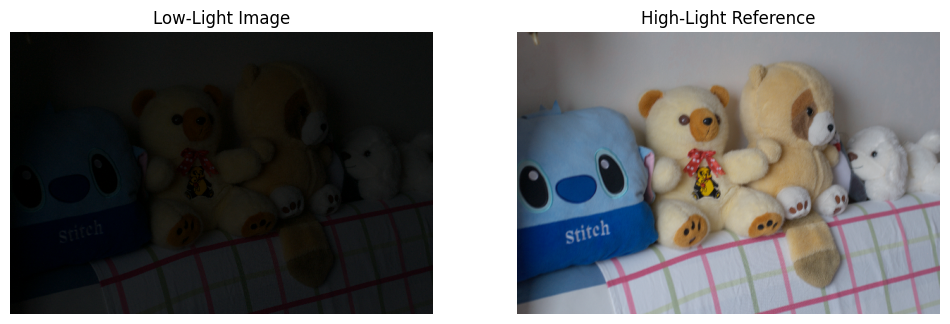

Image pair: 10.png


In [19]:
import matplotlib.pyplot as plt
from PIL import Image
import os

base = "/content/NightWatch/dataset/LOL/lol_dataset/our485"

low_path = os.path.join(base, "low")
high_path = os.path.join(base, "high")

filename = sorted([
    f for f in os.listdir(low_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])[0]

low_img = Image.open(os.path.join(low_path, filename))
high_img = Image.open(os.path.join(high_path, filename))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(low_img)
plt.title("Low-Light Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(high_img)
plt.title("High-Light Reference")
plt.axis("off")

plt.show()

print("Image pair:", filename)

In [20]:
import os

project_path = "/content/NightWatch"

for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d not in ["__pycache__", ".git"]]

    level = root.replace(project_path, "").count(os.sep)

    if level > 2:
        continue

    print("\n" + root)
    for file in files:
        print("  ", file)



/content/NightWatch

/content/NightWatch/models

/content/NightWatch/dataset

/content/NightWatch/dataset/LOL
   lol_dataset.zip

/content/NightWatch/logs

/content/NightWatch/checkpoints

/content/NightWatch/results

/content/NightWatch/outputs


In [21]:
import tensorflow as tf
import os

print("TensorFlow version:", tf.__version__)

dataset_path = "/content/NightWatch/dataset/LOL/lol_dataset"

for split in ["our485", "eval15"]:
    for category in ["low", "high"]:
        path = os.path.join(dataset_path, split, category)

        images = [
            f for f in os.listdir(path)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]

        print(f"{split}/{category}: {len(images)} images")

TensorFlow version: 2.21.0
our485/low: 485 images
our485/high: 485 images
eval15/low: 15 images
eval15/high: 15 images


In [22]:

%%writefile /content/NightWatch/data_loader.py

import os
import numpy as np
import tensorflow as tf

# Dataset configuration
PROJECT_DIR = "/content/NightWatch"

DATASET_DIR = os.path.join(
    PROJECT_DIR, "dataset", "LOL", "lol_dataset"
)

IMAGE_SIZE = (256, 384)  # Height, Width
BATCH_SIZE = 8
SEED = 42

VALID_EXTENSIONS = (".png", ".jpg", ".jpeg")


def get_image_pairs(split):

    low_dir = os.path.join(DATASET_DIR, split, "low")
    high_dir = os.path.join(DATASET_DIR, split, "high")

    if not os.path.isdir(low_dir) or not os.path.isdir(high_dir):
        raise FileNotFoundError(f"Dataset folders missing: {split}")

    low_files = sorted(
        f for f in os.listdir(low_dir)
        if f.lower().endswith(VALID_EXTENSIONS)
    )

    high_files = sorted(
        f for f in os.listdir(high_dir)
        if f.lower().endswith(VALID_EXTENSIONS)
    )

    if set(low_files) != set(high_files):
        raise ValueError(f"Image pairing mismatch in {split}")

    low_paths = [
        os.path.join(low_dir, f) for f in low_files
    ]

    high_paths = [
        os.path.join(high_dir, f) for f in low_files
    ]

    return low_paths, high_paths


def load_image(low_path, high_path):

    # Read low-light image
    low_image = tf.io.read_file(low_path)
    low_image = tf.io.decode_image(
        low_image, channels=3, expand_animations=False
    )

    # Read high-light reference
    high_image = tf.io.read_file(high_path)
    high_image = tf.io.decode_image(
        high_image, channels=3, expand_animations=False
    )

    low_image.set_shape([None, None, 3])
    high_image.set_shape([None, None, 3])

    # Resize images
    low_image = tf.image.resize(
        low_image, IMAGE_SIZE
    )

    high_image = tf.image.resize(
        high_image, IMAGE_SIZE
    )

    # Normalize pixel values to [0, 1]
    low_image = tf.cast(low_image, tf.float32) / 255.0
    high_image = tf.cast(high_image, tf.float32) / 255.0

    return low_image, high_image


def create_pipeline(low_paths, high_paths, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (low_paths, high_paths)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(low_paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


def build_datasets():

    # Load training and validation source pairs
    low_paths, high_paths = get_image_pairs("our485")

    # Reproducible 90:10 split
    indices = np.random.default_rng(SEED).permutation(
        len(low_paths)
    )

    split_index = int(len(indices) * 0.9)

    train_indices = indices[:split_index]
    val_indices = indices[split_index:]

    train_low = [low_paths[i] for i in train_indices]
    train_high = [high_paths[i] for i in train_indices]

    val_low = [low_paths[i] for i in val_indices]
    val_high = [high_paths[i] for i in val_indices]

    # Load independent evaluation dataset
    test_low, test_high = get_image_pairs("eval15")

    # Create TensorFlow pipelines
    train_ds = create_pipeline(
        train_low, train_high, training=True
    )

    val_ds = create_pipeline(
        val_low, val_high
    )

    test_ds = create_pipeline(
        test_low, test_high
    )

    print("NightWatch Data Pipeline")
    print("-----------------------")
    print("Training pairs:", len(train_low))
    print("Validation pairs:", len(val_low))
    print("Testing pairs:", len(test_low))
    print("Image size:", IMAGE_SIZE)
    print("Batch size:", BATCH_SIZE)

    return train_ds, val_ds, test_ds


if __name__ == "__main__":

    train_ds, val_ds, test_ds = build_datasets()

    for low, high in train_ds.take(1):
        print("\nSample batch verification")
        print("Low-light shape:", low.shape)
        print("High-light shape:", high.shape)
        print("Minimum pixel:", tf.reduce_min(low).numpy())
        print("Maximum pixel:", tf.reduce_max(low).numpy())


Writing /content/NightWatch/data_loader.py


In [23]:
import sys

sys.path.insert(0, "/content/NightWatch")

from data_loader import build_datasets

train_ds, val_ds, test_ds = build_datasets()

NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8


In [24]:
for low, high in train_ds.take(1):

    print("Low image batch:", low.shape)
    print("High image batch:", high.shape)

    print("Low pixel range:",
          low.numpy().min(),
          low.numpy().max())

    print("High pixel range:",
          high.numpy().min(),
          high.numpy().max())

Low image batch: (8, 256, 384, 3)
High image batch: (8, 256, 384, 3)
Low pixel range: 0.0 1.0
High pixel range: 0.0 1.0


In [25]:

%%writefile /content/NightWatch/models/unet.py

import tensorflow as tf
from tensorflow.keras import layers, Model


def conv_block(inputs, filters):

    x = layers.Conv2D(
        filters, 3, padding="same",
        kernel_initializer="he_normal"
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filters, 3, padding="same",
        kernel_initializer="he_normal"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x


def build_unet(input_shape=(256, 384, 3)):

    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 256)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    b = conv_block(p4, 512)

    # Decoder
    u4 = layers.Conv2DTranspose(
        256, 2, strides=2, padding="same"
    )(b)

    u4 = layers.Concatenate()([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = layers.Conv2DTranspose(
        128, 2, strides=2, padding="same"
    )(c5)

    u3 = layers.Concatenate()([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = layers.Conv2DTranspose(
        64, 2, strides=2, padding="same"
    )(c6)

    u2 = layers.Concatenate()([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = layers.Conv2DTranspose(
        32, 2, strides=2, padding="same"
    )(c7)

    u1 = layers.Concatenate()([u1, c1])
    c8 = conv_block(u1, 32)

    # Enhanced RGB image
    outputs = layers.Conv2D(
        3, 1, activation="sigmoid"
    )(c8)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="NightWatch_UNet"
    )

    return model


Writing /content/NightWatch/models/unet.py


In [26]:
import sys

sys.path.insert(0, "/content/NightWatch")

from models.unet import build_unet

model = build_unet()

model.summary()

Model: "NightWatch_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 384,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 384,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 384,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 384,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 384,  │      9,248 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 384,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 256, 384,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 192,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 192,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 192,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 128, 192,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 192,  │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 192,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 192,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 96,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 96,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 96,    │        512 │ conv2d_4[0][0]  

 Total params: 7,771,939 (29.65 MB)

 Trainable params: 7,766,051 (29.63 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [27]:
for low, high in train_ds.take(1):

    prediction = model(low)

    print("Input shape:", low.shape)
    print("Output shape:", prediction.shape)
    print("Output minimum:", prediction.numpy().min())
    print("Output maximum:", prediction.numpy().max())

Input shape: (8, 256, 384, 3)
Output shape: (8, 256, 384, 3)
Output minimum: 0.4624903
Output maximum: 0.6066351


In [28]:

%%writefile /content/NightWatch/models/losses.py

import tensorflow as tf


def combined_loss(y_true, y_pred):

    # Pixel-level L1 loss
    l1_loss = tf.reduce_mean(
        tf.abs(y_true - y_pred)
    )

    # Structural Similarity Index
    ssim_value = tf.image.ssim(
        y_true,
        y_pred,
        max_val=1.0
    )

    ssim_loss = 1.0 - tf.reduce_mean(ssim_value)

    # Weighted combined loss
    total_loss = (
        0.8 * l1_loss +
        0.2 * ssim_loss
    )

    return total_loss


def calculate_metrics(y_true, y_pred):

    psnr = tf.reduce_mean(
        tf.image.psnr(y_true, y_pred, max_val=1.0)
    )

    ssim = tf.reduce_mean(
        tf.image.ssim(y_true, y_pred, max_val=1.0)
    )

    return psnr, ssim


Writing /content/NightWatch/models/losses.py


In [29]:
import sys
sys.path.insert(0, "/content/NightWatch")

from models.losses import combined_loss, calculate_metrics

for low, high in train_ds.take(1):

    prediction = model(low, training=False)

    loss = combined_loss(high, prediction)

    psnr, ssim = calculate_metrics(high, prediction)

    print("Combined Loss:", loss.numpy())
    print("PSNR:", psnr.numpy())
    print("SSIM:", ssim.numpy())

Combined Loss: 0.2750464
PSNR: 12.829512
SSIM: 0.44611263


In [30]:

%%writefile /content/NightWatch/train.py

import os
import tensorflow as tf

from data_loader import build_datasets
from models.unet import build_unet
from models.losses import combined_loss


# Project directories
PROJECT_DIR = "/content/NightWatch"

CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
LOG_DIR = os.path.join(PROJECT_DIR, "logs")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

# Training configuration
EPOCHS = 5
LEARNING_RATE = 0.0001

print("Loading datasets...")

train_ds, val_ds, test_ds = build_datasets()

print("\nBuilding U-Net model...")

model = build_unet()

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=combined_loss
)

# Save best model
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(
        CHECKPOINT_DIR, "best_nightwatch.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Stop when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate when progress plateaus
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# Save training history
csv_logger = tf.keras.callbacks.CSVLogger(
    os.path.join(LOG_DIR, "training_history.csv"),
    append=True
)

print("\nStarting NightWatch training...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr,
        csv_logger
    ]
)

# Save final model
model.save(
    os.path.join(CHECKPOINT_DIR, "final_nightwatch.keras")
)

print("\nTraining completed!")
print("Best model:", os.path.join(
    CHECKPOINT_DIR, "best_nightwatch.keras"
))
print("Training history:", os.path.join(
    LOG_DIR, "training_history.csv"
))


Writing /content/NightWatch/train.py


In [31]:
import tensorflow as tf

print("Available GPUs:", tf.config.list_physical_devices("GPU"))

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [32]:
!python /content/NightWatch/train.py

Loading datasets...
W0000 00:00:1794981036.988606    6160 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8

Building U-Net model...

Starting NightWatch training...
Epoch 1/5
W0000 00:00:1794981053.237175    6204 assert_op.cc:39] Ignoring Assert operator compile_loss/combined_loss/SSIM/Assert/Assert
W0000 00:00:1794981053.237802    6204 assert_op.cc:39] Ignoring Assert operator compile_loss/combined_loss/SSIM/Assert_1/Assert
W0000 00:00:1794981053.238370    6204 assert_op.cc:39] Ignoring Assert operator compile_loss/combined_loss/SSIM/Assert_2/Assert
W0000 00:00:1794981053.238834    6204 assert_op.cc:39] Ignoring Assert operator compile_loss/combined_loss/SSIM/Assert_3/Assert
W0000 00:00:1794981070.700741    6204 bfc_allocator.cc:502] Allo

In [33]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.insert(0, "/content/NightWatch")

from data_loader import build_datasets

# Load evaluation dataset
train_ds, val_ds, test_ds = build_datasets()

# Load best trained model
model = tf.keras.models.load_model(
    "/content/NightWatch/checkpoints/best_nightwatch.keras",
    compile=False
)

psnr_scores = []
ssim_scores = []

# Evaluate all test images
for low, high in test_ds:

    enhanced = model(low, training=False)

    psnr = tf.image.psnr(
        high, enhanced, max_val=1.0
    )

    ssim = tf.image.ssim(
        high, enhanced, max_val=1.0
    )

    psnr_scores.extend(psnr.numpy())
    ssim_scores.extend(ssim.numpy())

print("\nNightWatch Evaluation Results")
print("-----------------------------")
print("Test images:", len(psnr_scores))
print("Average PSNR:", np.mean(psnr_scores))
print("Average SSIM:", np.mean(ssim_scores))


NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8

NightWatch Evaluation Results
-----------------------------
Test images: 15
Average PSNR: 13.380177
Average SSIM: 0.5654917


In [34]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.insert(0, "/content/NightWatch")

from data_loader import build_datasets

# Load evaluation dataset
train_ds, val_ds, test_ds = build_datasets()

# Load best trained model
model = tf.keras.models.load_model(
    "/content/NightWatch/checkpoints/best_nightwatch.keras",
    compile=False
)

psnr_scores = []
ssim_scores = []

# Evaluate all test images
for low, high in test_ds:

    enhanced = model(low, training=False)

    psnr = tf.image.psnr(
        high, enhanced, max_val=1.0
    )

    ssim = tf.image.ssim(
        high, enhanced, max_val=1.0
    )

    psnr_scores.extend(psnr.numpy())
    ssim_scores.extend(ssim.numpy())

print("\nNightWatch Evaluation Results")
print("-----------------------------")
print("Test images:", len(psnr_scores))
print("Average PSNR:", np.mean(psnr_scores))
print("Average SSIM:", np.mean(ssim_scores))


NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8

NightWatch Evaluation Results
-----------------------------
Test images: 15
Average PSNR: 13.380177
Average SSIM: 0.5654917


In [35]:

import numpy as np
import tensorflow as tf

original_psnr = []
enhanced_psnr = []

original_ssim = []
enhanced_ssim = []

for low, high in test_ds:

    prediction = model(low, training=False)

    # Original low-light image vs reference
    p1 = tf.image.psnr(low, high, max_val=1.0)
    s1 = tf.image.ssim(low, high, max_val=1.0)

    # Enhanced image vs reference
    p2 = tf.image.psnr(prediction, high, max_val=1.0)
    s2 = tf.image.ssim(prediction, high, max_val=1.0)

    original_psnr.extend(p1.numpy())
    enhanced_psnr.extend(p2.numpy())

    original_ssim.extend(s1.numpy())
    enhanced_ssim.extend(s2.numpy())


print("NIGHTWATCH PERFORMANCE COMPARISON")
print("---------------------------------")

print("Original PSNR:", np.mean(original_psnr))
print("Enhanced PSNR:", np.mean(enhanced_psnr))

print("Original SSIM:", np.mean(original_ssim))
print("Enhanced SSIM:", np.mean(enhanced_ssim))

print("---------------------------------")

print("PSNR improvement:",
      np.mean(enhanced_psnr) - np.mean(original_psnr))

print("SSIM improvement:",
      np.mean(enhanced_ssim) - np.mean(original_ssim))


NIGHTWATCH PERFORMANCE COMPARISON
---------------------------------
Original PSNR: 7.792346
Enhanced PSNR: 13.380177
Original SSIM: 0.1931455
Enhanced SSIM: 0.5654917
---------------------------------
PSNR improvement: 5.5878305
SSIM improvement: 0.37234616


In [36]:

import os
import numpy as np
import tensorflow as tf
from PIL import Image

output_dir = "/content/NightWatch/results/eval15"
os.makedirs(output_dir, exist_ok=True)

low_paths, high_paths = __import__(
    "data_loader"
).get_image_pairs("eval15")

for index, (low, high) in enumerate(test_ds.unbatch()):

    prediction = model(
        tf.expand_dims(low, axis=0),
        training=False
    )[0]

    enhanced = np.clip(
        prediction.numpy() * 255, 0, 255
    ).astype(np.uint8)

    filename = os.path.basename(low_paths[index])

    Image.fromarray(enhanced).save(
        os.path.join(output_dir, filename)
    )

print("Enhanced images saved:", len(os.listdir(output_dir)))
print("Output directory:", output_dir)


Enhanced images saved: 15
Output directory: /content/NightWatch/results/eval15


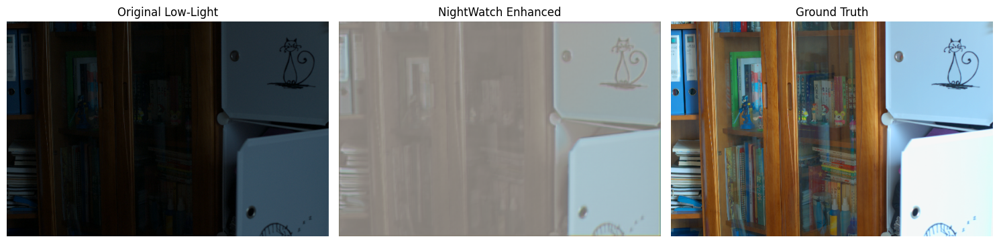

In [37]:
import matplotlib.pyplot as plt
import os
from PIL import Image

base = "/content/NightWatch/dataset/LOL/lol_dataset/eval15"

low_dir = os.path.join(base, "low")
high_dir = os.path.join(base, "high")
enhanced_dir = "/content/NightWatch/results/eval15"

filename = sorted(os.listdir(enhanced_dir))[0]

low = Image.open(os.path.join(low_dir, filename))
enhanced = Image.open(os.path.join(enhanced_dir, filename))
high = Image.open(os.path.join(high_dir, filename))

plt.figure(figsize=(15, 5))

for i, (img, title) in enumerate([
    (low, "Original Low-Light"),
    (enhanced, "NightWatch Enhanced"),
    (high, "Ground Truth")
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

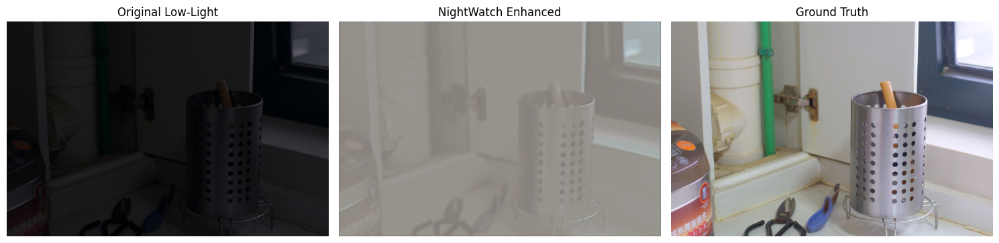

Image: 111.png


In [38]:
import os
import matplotlib.pyplot as plt
from PIL import Image

base = "/content/NightWatch/dataset/LOL/lol_dataset/eval15"

low_dir = os.path.join(base, "low")
high_dir = os.path.join(base, "high")
enhanced_dir = "/content/NightWatch/results/eval15"

files = sorted([
    f for f in os.listdir(enhanced_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

filename = files[1]  # Second image

low = Image.open(os.path.join(low_dir, filename))
enhanced = Image.open(os.path.join(enhanced_dir, filename))
high = Image.open(os.path.join(high_dir, filename))

plt.figure(figsize=(15, 5))

for i, (img, title) in enumerate([
    (low, "Original Low-Light"),
    (enhanced, "NightWatch Enhanced"),
    (high, "Ground Truth")
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Image:", filename)

In [42]:

%%writefile /content/NightWatch/models/resunet.py

import tensorflow as tf
from tensorflow.keras import layers, Model


# ==========================================
# 1. RESIDUAL BLOCK
# ==========================================

def residual_block(inputs, filters):

    shortcut = inputs

    # First convolution
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        kernel_initializer="he_normal"
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Second convolution
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    x = layers.BatchNormalization()(x)

    # Adjust shortcut channels if required
    if inputs.shape[-1] != filters:

        shortcut = layers.Conv2D(
            filters,
            kernel_size=1,
            padding="same"
        )(shortcut)

        shortcut = layers.BatchNormalization()(shortcut)

    # Residual connection
    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x


# ==========================================
# 2. ATTENTION GATE
# ==========================================

def attention_gate(skip, gate, filters):

    # Transform encoder features
    theta = layers.Conv2D(
        filters,
        kernel_size=1,
        padding="same"
    )(skip)

    # Transform decoder features
    phi = layers.Conv2D(
        filters,
        kernel_size=1,
        padding="same"
    )(gate)

    # Combine features
    combined = layers.Add()([theta, phi])
    combined = layers.ReLU()(combined)

    # Generate attention coefficients
    attention = layers.Conv2D(
        1,
        kernel_size=1,
        activation="sigmoid"
    )(combined)

    # Apply attention to skip features
    attended = layers.Multiply()([
        skip,
        attention
    ])

    return attended


# ==========================================
# 3. DECODER BLOCK
# ==========================================

def decoder_block(inputs, skip, filters):

    # Upsampling
    x = layers.Conv2DTranspose(
        filters,
        kernel_size=2,
        strides=2,
        padding="same"
    )(inputs)

    # Attention-filtered skip connection
    attended_skip = attention_gate(
        skip,
        x,
        filters
    )

    # Concatenate features
    x = layers.Concatenate()([
        x,
        attended_skip
    ])

    # Residual feature refinement
    x = residual_block(x, filters)

    return x


# ==========================================
# 4. RESIDUAL ATTENTION U-NET
# ==========================================

def build_resunet(input_shape=(256, 384, 3)):

    inputs = layers.Input(
        shape=input_shape,
        name="low_light_input"
    )

    # --------------------------------------
    # ENCODER
    # --------------------------------------

    c1 = residual_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = residual_block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)

    c3 = residual_block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)

    c4 = residual_block(p3, 128)
    p4 = layers.MaxPooling2D()(c4)

    # --------------------------------------
    # BOTTLENECK
    # --------------------------------------

    bottleneck = residual_block(p4, 256)

    # --------------------------------------
    # DECODER
    # --------------------------------------

    d4 = decoder_block(
        bottleneck, c4, 128
    )

    d3 = decoder_block(
        d4, c3, 64
    )

    d2 = decoder_block(
        d3, c2, 32
    )

    d1 = decoder_block(
        d2, c1, 16
    )

    # --------------------------------------
    # RESIDUAL IMAGE CORRECTION
    # --------------------------------------

    residual = layers.Conv2D(
        filters=3,
        kernel_size=3,
        padding="same",
        activation="tanh",
        name="residual_prediction"
    )(d1)

    # Limit correction magnitude
    residual = layers.Rescaling(
        scale=0.25,
        name="correction_scaling"
    )(residual)

    # Add predicted correction to original input
    corrected = layers.Add(
        name="image_correction"
    )([inputs, residual])

    # Restrict final pixel values to [0, 1]
    outputs = layers.ReLU(
        max_value=1.0,
        name="residual_image_output"
    )(corrected)

    # --------------------------------------
    # BUILD MODEL
    # --------------------------------------

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="NightWatch_Residual_Attention_UNet"
    )

    return model


Overwriting /content/NightWatch/models/resunet.py


In [43]:

import sys
import tensorflow as tf
import importlib

sys.path.insert(0, "/content/NightWatch")

import models.resunet as resunet

# Reload updated architecture
importlib.reload(resunet)

# Build model
res_model = resunet.build_resunet()

print("Residual Attention U-Net created successfully!")

# Display architecture
res_model.summary()


Residual Attention U-Net created successfully!


Model: "NightWatch_Residual_Attention_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ low_light_input     │ (None, 256, 384,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_59 (Conv2D)  │ (None, 256, 384,  │        448 │ low_light_input[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 384,  │         64 │ conv2d_59[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_40 (ReLU)     │ (None, 256, 384,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_60 (Conv2D)  │ (None, 256, 384,  │      2,320 │ re_lu_40[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_61 (Conv2D)  │ (None, 256, 384,  │         64 │ low_light_input[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 384,  │         64 │ conv2d_60[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 384,  │         64 │ conv2d_61[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 256, 384,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_41 (ReLU)     │ (None, 256, 384,  │          0 │ add_13[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 128, 192,  │          0 │ re_lu_41[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_62 (Conv2D)  │ (None, 128, 192,  │      4,640 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 192,  │        128 │ conv2d_62[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_42 (ReLU)     │ (None, 128, 192,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_63 (Conv2D)  │ (None, 128, 192,  │      9,248 │ re_lu_42[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_64 (Conv2D)  │ (None, 128, 192,  │        544 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 192,  │        128 │ conv2d_63[0][0] 

 Total params: 2,082,423 (7.94 MB)

 Trainable params: 2,078,007 (7.93 MB)

 Non-trainable params: 4,416 (17.25 KB)

In [44]:

# Test forward pass
for low, high in train_ds.take(1):

    prediction = res_model(
        low,
        training=False
    )

    print("\nMODEL VERIFICATION")
    print("------------------")

    print("Input shape:", low.shape)
    print("Output shape:", prediction.shape)

    print(
        "Output minimum:",
        tf.reduce_min(prediction).numpy()
    )

    print(
        "Output maximum:",
        tf.reduce_max(prediction).numpy()
    )

    print(
        "Contains NaN:",
        tf.reduce_any(
            tf.math.is_nan(prediction)
        ).numpy()
    )



MODEL VERIFICATION
------------------
Input shape: (8, 256, 384, 3)
Output shape: (8, 256, 384, 3)
Output minimum: 0.0
Output maximum: 0.6213601
Contains NaN: False


In [45]:
!python /content/NightWatch/train_resunet.py


python3: can't open file '/content/NightWatch/train_resunet.py': [Errno 2] No such file or directory


In [46]:
!ls -la /content/NightWatch

total 44
drwxr-xr-x 9 root root 4096 Nov 18 05:50 .
drwxr-xr-x 1 root root 4096 Nov 18 05:31 ..
drwxr-xr-x 2 root root 4096 Nov 18 05:56 checkpoints
-rw-r--r-- 1 root root 4083 Nov 18 05:44 data_loader.py
drwxr-xr-x 3 root root 4096 Nov 18 05:33 dataset
drwxr-xr-x 2 root root 4096 Nov 18 05:50 logs
drwxr-xr-x 3 root root 4096 Nov 18 06:11 models
drwxr-xr-x 2 root root 4096 Nov 18 05:31 outputs
drwxr-xr-x 2 root root 4096 Nov 18 05:45 __pycache__
drwxr-xr-x 3 root root 4096 Nov 18 06:04 results
-rw-r--r-- 1 root root 1968 Nov 18 05:50 train.py


In [47]:
%%writefile /content/NightWatch/train_resunet.py

import os
import tensorflow as tf

from data_loader import build_datasets
from models.resunet import build_resunet
from models.losses import combined_loss

EPOCHS = 30
BATCH_SIZE = 4
LEARNING_RATE = 0.0001

BASE_DIR = "/content/NightWatch"
CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
LOG_DIR = os.path.join(BASE_DIR, "logs")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

print("Loading datasets...")

train_ds, val_ds, test_ds = build_datasets()

train_ds = train_ds.unbatch().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.unbatch().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Building Residual Attention U-Net...")

model = build_resunet(input_shape=(256, 384, 3))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=combined_loss
)

model.summary()

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(CHECKPOINT_DIR, "best_resunet.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        os.path.join(LOG_DIR, "resunet_history.csv"),
        append=False
    )
]

print("\nStarting Residual Attention U-Net training...\n")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

model.save(os.path.join(CHECKPOINT_DIR, "final_resunet.keras"))

print("\nTraining completed successfully!")

Writing /content/NightWatch/train_resunet.py


In [48]:
!ls -l /content/NightWatch/train_resunet.py

-rw-r--r-- 1 root root 1759 Nov 18 06:20 /content/NightWatch/train_resunet.py


In [49]:
%cd /content/NightWatch
!python train_resunet.py

/content/NightWatch
Loading datasets...
W0000 00:00:1794982908.068637   17055 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8
Building Residual Attention U-Net...
Model: "NightWatch_Residual_Attention_UNet"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ low_light_input     │ (None, 256, 384,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 384,  │        448 │ low_light_input[… │
│ 

In [50]:
 %%writefile /content/NightWatch/evaluate_resunet.py

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from PIL import Image

from data_loader import build_datasets

BASE_DIR = "/content/NightWatch"

MODEL_PATH = os.path.join(
    BASE_DIR, "checkpoints", "best_resunet.keras"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "results", "resunet_eval15"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Loading best Residual Attention U-Net...")

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Loading test dataset...")

train_ds, val_ds, test_ds = build_datasets()

low_dir = Path(BASE_DIR) / "dataset" / "LOL" / "lol_dataset" / "eval15" / "low"

image_extensions = {".png", ".jpg", ".jpeg"}

image_paths = sorted([
    p for p in low_dir.iterdir()
    if p.suffix.lower() in image_extensions
])

results = []

image_index = 0

print("\nEvaluating test images...\n")

for low_images, high_images in test_ds:

    predictions = model(low_images, training=False)

    predictions = tf.clip_by_value(
        predictions, 0.0, 1.0
    )

    baseline_psnr = tf.image.psnr(
        high_images, low_images, max_val=1.0
    )

    enhanced_psnr = tf.image.psnr(
        high_images, predictions, max_val=1.0
    )

    baseline_ssim = tf.image.ssim(
        high_images, low_images, max_val=1.0
    )

    enhanced_ssim = tf.image.ssim(
        high_images, predictions, max_val=1.0
    )

    for i in range(low_images.shape[0]):

        filename = image_paths[image_index].name

        output_image = (
            predictions[i].numpy() * 255
        ).astype(np.uint8)

        Image.fromarray(output_image).save(
            os.path.join(OUTPUT_DIR, filename)
        )

        results.append({
            "Image": filename,
            "Baseline_PSNR": float(baseline_psnr[i].numpy()),
            "Enhanced_PSNR": float(enhanced_psnr[i].numpy()),
            "Baseline_SSIM": float(baseline_ssim[i].numpy()),
            "Enhanced_SSIM": float(enhanced_ssim[i].numpy())
        })

        image_index += 1

assert image_index == len(image_paths), (
    f"Evaluated {image_index} images, "
    f"but found {len(image_paths)} test images."
)

df = pd.DataFrame(results)

df["PSNR_Improvement"] = (
    df["Enhanced_PSNR"] - df["Baseline_PSNR"]
)

df["SSIM_Improvement"] = (
    df["Enhanced_SSIM"] - df["Baseline_SSIM"]
)

csv_path = os.path.join(
    OUTPUT_DIR, "evaluation_metrics.csv"
)

df.to_csv(csv_path, index=False)

print("\nINDIVIDUAL IMAGE RESULTS")
print(df.round(4).to_string(index=False))

print("\nAVERAGE RESULTS")
print("Baseline PSNR:", round(df["Baseline_PSNR"].mean(), 4))
print("Enhanced PSNR:", round(df["Enhanced_PSNR"].mean(), 4))
print("Baseline SSIM:", round(df["Baseline_SSIM"].mean(), 4))
print("Enhanced SSIM:", round(df["Enhanced_SSIM"].mean(), 4))

print("\nAVERAGE IMPROVEMENT")
print("PSNR:", round(df["PSNR_Improvement"].mean(), 4))
print("SSIM:", round(df["SSIM_Improvement"].mean(), 4))

print("\nEnhanced images saved in:", OUTPUT_DIR)
print("Metrics saved in:", csv_path)

Writing /content/NightWatch/evaluate_resunet.py


In [51]:
%cd /content/NightWatch
!python evaluate_resunet.py

/content/NightWatch
Loading best Residual Attention U-Net...
W0000 00:00:1794983594.297305   23615 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Loading test dataset...
NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8

Evaluating test images...


INDIVIDUAL IMAGE RESULTS
  Image  Baseline_PSNR  Enhanced_PSNR  Baseline_SSIM  Enhanced_SSIM  PSNR_Improvement  SSIM_Improvement
  1.png         7.2308        12.3795         0.2298         0.7085            5.1487            0.4788
111.png         5.6160        10.7074         0.1865         0.7004            5.0914            0.5138
146.png         6.6442        12.1544         0.2620         0.7388            5.5102            0.4768
179.png        12.4085        18.0991         0.4389         0.7325            5.6906            0.2936
 22

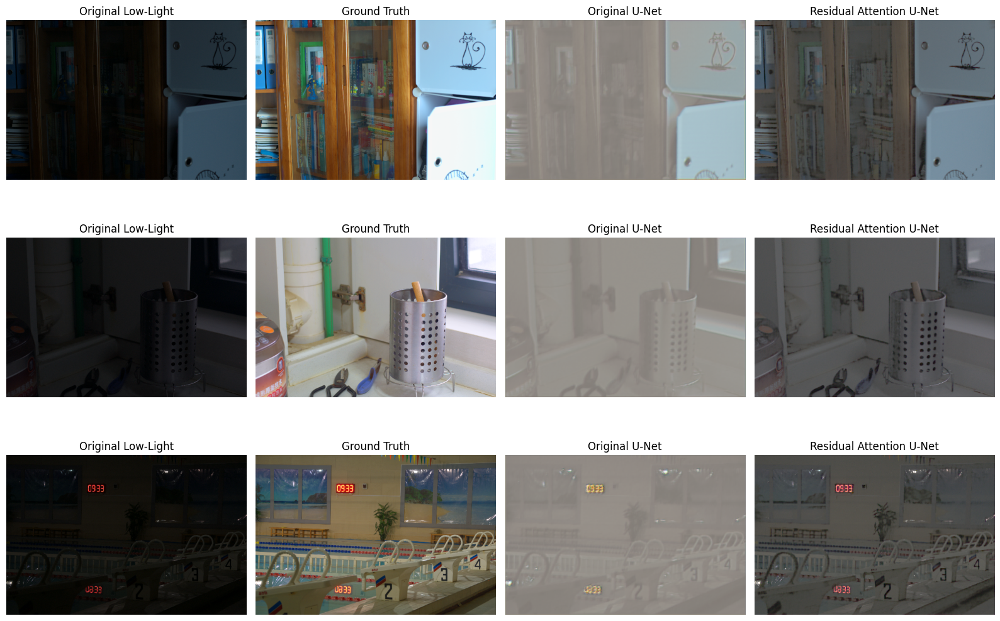

In [52]:
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from pathlib import Path
import numpy as np

base = Path("/content/NightWatch")

low_dir = base / "dataset/LOL/lol_dataset/eval15/low"
high_dir = base / "dataset/LOL/lol_dataset/eval15/high"
unet_dir = base / "results/eval15"
resunet_dir = base / "results/resunet_eval15"

filenames = ["1.png", "111.png", "748.png"]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))

for row, filename in enumerate(filenames):

    paths = [
        low_dir / filename,
        high_dir / filename,
        unet_dir / filename,
        resunet_dir / filename
    ]

    titles = [
        "Original Low-Light",
        "Ground Truth",
        "Original U-Net",
        "Residual Attention U-Net"
    ]

    for col, (path, title) in enumerate(zip(paths, titles)):

        img = Image.open(path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(title)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(filename, fontsize=12)

plt.tight_layout()
plt.show()

In [53]:
%%writefile /content/NightWatch/train_resunet_aug.py

import os
import tensorflow as tf

from data_loader import build_datasets
from models.resunet import build_resunet
from models.losses import combined_loss

# Configuration
EPOCHS = 30
BATCH_SIZE = 4
LEARNING_RATE = 0.0001

BASE_DIR = "/content/NightWatch"
CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
LOG_DIR = os.path.join(BASE_DIR, "logs")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)


# Paired horizontal flip augmentation
def augment_pair(low, high):

    flip = tf.random.uniform(()) > 0.5

    low = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(low),
        lambda: low
    )

    high = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(high),
        lambda: high
    )

    return low, high


print("Loading datasets...")

train_ds, val_ds, test_ds = build_datasets()

# Unbatch before augmentation
train_ds = train_ds.unbatch()

# Shuffle and augment paired images
train_ds = train_ds.shuffle(
    436,
    seed=42,
    reshuffle_each_iteration=True
)

train_ds = train_ds.map(
    augment_pair,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

# Validation remains unchanged
val_ds = val_ds.unbatch().batch(BATCH_SIZE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

print("Training examples:", 436)
print("Validation examples:", 49)
print("Test examples:", 15)

print("\nBuilding Residual Attention U-Net...")

model = build_resunet(
    input_shape=(256, 384, 3)
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=combined_loss
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(
            CHECKPOINT_DIR,
            "best_resunet_aug.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        os.path.join(LOG_DIR, "resunet_aug_history.csv"),
        append=False
    )
]

print("\nStarting Experiment 3: Augmented Training")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

model.save(
    os.path.join(
        CHECKPOINT_DIR,
        "final_resunet_aug.keras"
    )
)

print("\nExperiment 3 completed!")

Writing /content/NightWatch/train_resunet_aug.py


In [54]:
!ls -lh /content/NightWatch/train_resunet_aug.py

-rw-r--r-- 1 root root 2.6K Nov 18 06:37 /content/NightWatch/train_resunet_aug.py


In [55]:
%cd /content/NightWatch
!python train_resunet_aug.py

/content/NightWatch
Loading datasets...
W0000 00:00:1794983921.875600   25131 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8
Training examples: 436
Validation examples: 49
Test examples: 15

Building Residual Attention U-Net...

Starting Experiment 3: Augmented Training
Epoch 1/30
W0000 00:00:1794983952.391686   25180 assert_op.cc:39] Ignoring Assert operator compile_loss/combined_loss/SSIM/Assert/Assert
W0000 00:00:1794983952.391817   25180 assert_op.cc:39] Ignoring Assert operator compile_loss/combined_loss/SSIM/Assert_1/Assert
W0000 00:00:1794983952.391997   25180 assert_op.cc:39] Ignoring Assert operator compile_loss/combined_loss/SSIM/Assert_2/Assert
W0000 00:00:1794983952.392104   25180 assert_op.cc:39] Ignoring Assert operator com

In [56]:
%%writefile /content/NightWatch/evaluate_resunet_aug.py

import os
import tensorflow as tf
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image
from data_loader import build_datasets

BASE_DIR = "/content/NightWatch"

MODEL_PATH = os.path.join(
    BASE_DIR, "checkpoints", "best_resunet_aug.keras"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "results", "resunet_aug_eval15"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Loading augmented Residual Attention U-Net...")

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Loading test dataset...")

_, _, test_ds = build_datasets()

low_dir = Path(
    BASE_DIR / Path("dataset/LOL/lol_dataset/eval15/low")
)

image_paths = sorted([
    p for p in low_dir.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
])

results = []
image_index = 0

for low_images, high_images in test_ds:

    predictions = model(low_images, training=False)
    predictions = tf.clip_by_value(predictions, 0.0, 1.0)

    baseline_psnr = tf.image.psnr(
        high_images, low_images, max_val=1.0
    )

    enhanced_psnr = tf.image.psnr(
        high_images, predictions, max_val=1.0
    )

    baseline_ssim = tf.image.ssim(
        high_images, low_images, max_val=1.0
    )

    enhanced_ssim = tf.image.ssim(
        high_images, predictions, max_val=1.0
    )

    for i in range(low_images.shape[0]):

        filename = image_paths[image_index].name

        output = (
            predictions[i].numpy() * 255
        ).round().clip(0, 255).astype(np.uint8)

        Image.fromarray(output).save(
            os.path.join(OUTPUT_DIR, filename)
        )

        results.append({
            "Image": filename,
            "Baseline_PSNR": float(baseline_psnr[i]),
            "Enhanced_PSNR": float(enhanced_psnr[i]),
            "Baseline_SSIM": float(baseline_ssim[i]),
            "Enhanced_SSIM": float(enhanced_ssim[i])
        })

        image_index += 1

assert image_index == len(image_paths)

df = pd.DataFrame(results)

df["PSNR_Improvement"] = (
    df["Enhanced_PSNR"] - df["Baseline_PSNR"]
)

df["SSIM_Improvement"] = (
    df["Enhanced_SSIM"] - df["Baseline_SSIM"]
)

df.to_csv(
    os.path.join(OUTPUT_DIR, "evaluation_metrics.csv"),
    index=False
)

print("\nINDIVIDUAL RESULTS")
print(df.round(4).to_string(index=False))

print("\nAVERAGE RESULTS")
print(df.mean(numeric_only=True).round(4))

print("\nSaved enhanced images to:", OUTPUT_DIR)

Writing /content/NightWatch/evaluate_resunet_aug.py


In [57]:
%cd /content/NightWatch
!python evaluate_resunet_aug.py

/content/NightWatch
Loading augmented Residual Attention U-Net...
W0000 00:00:1794984638.363559   31813 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Loading test dataset...
NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8

INDIVIDUAL RESULTS
  Image  Baseline_PSNR  Enhanced_PSNR  Baseline_SSIM  Enhanced_SSIM  PSNR_Improvement  SSIM_Improvement
  1.png         7.2308        12.4081         0.2298         0.7175            5.1773            0.4878
111.png         5.6160        10.6906         0.1865         0.7058            5.0746            0.5192
146.png         6.6442        12.2284         0.2620         0.7449            5.5841            0.4829
179.png        12.4085        18.4228         0.4389         0.7428            6.0144            0.3038
 22.png         6.1142        10

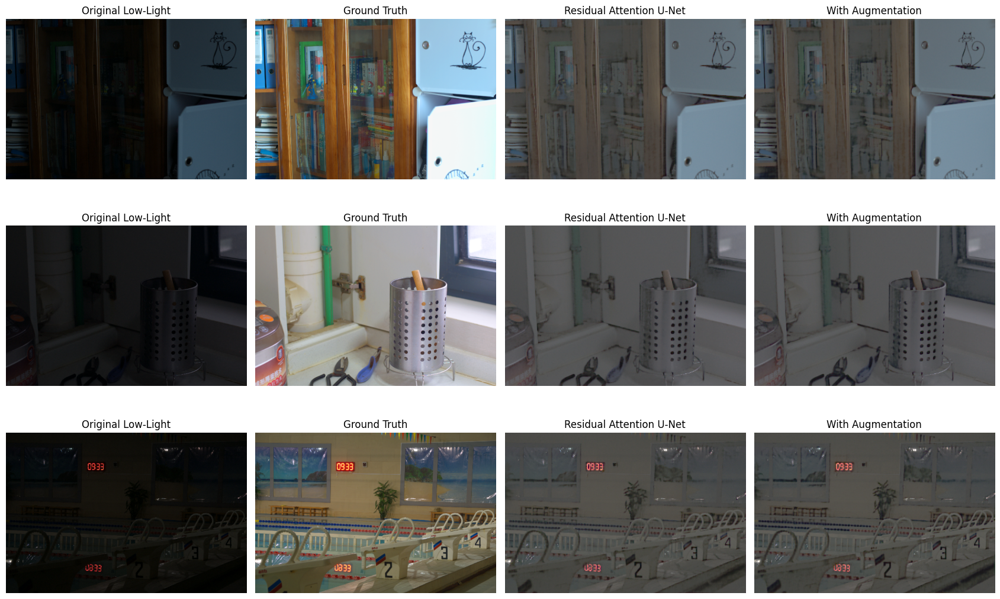

In [58]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

base = Path("/content/NightWatch")

folders = [
    base / "dataset/LOL/lol_dataset/eval15/low",
    base / "dataset/LOL/lol_dataset/eval15/high",
    base / "results/resunet_eval15",
    base / "results/resunet_aug_eval15"
]

titles = [
    "Original Low-Light",
    "Ground Truth",
    "Residual Attention U-Net",
    "With Augmentation"
]

filenames = ["1.png", "111.png", "748.png"]

fig, axes = plt.subplots(3, 4, figsize=(17, 11))

for r, filename in enumerate(filenames):
    for c, folder in enumerate(folders):
        img = Image.open(folder / filename).convert("RGB")
        axes[r, c].imshow(img)
        axes[r, c].set_title(titles[c])
        axes[r, c].axis("off")

    axes[r, 0].set_ylabel(filename)

plt.tight_layout()
plt.show()

In [59]:
%%writefile /content/NightWatch/models/advanced_losses.py

import tensorflow as tf


def build_advanced_loss(input_shape=(256, 384, 3)):

    # Load pretrained VGG16 for perceptual feature extraction
    vgg = tf.keras.applications.VGG16(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )

    # Use intermediate features
    feature_extractor = tf.keras.Model(
        inputs=vgg.input,
        outputs=vgg.get_layer("block3_conv3").output
    )

    feature_extractor.trainable = False

    def calculate_components(y_true, y_pred):

        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)

        # 1. Pixel reconstruction loss
        l1_loss = tf.reduce_mean(
            tf.abs(y_true - y_pred)
        )

        # 2. Structural similarity loss
        ssim_loss = 1.0 - tf.reduce_mean(
            tf.image.ssim(
                y_true,
                y_pred,
                max_val=1.0
            )
        )

        # 3. Perceptual loss
        true_vgg = tf.keras.applications.vgg16.preprocess_input(
            y_true * 255.0
        )

        pred_vgg = tf.keras.applications.vgg16.preprocess_input(
            y_pred * 255.0
        )

        true_features = tf.stop_gradient(
            feature_extractor(true_vgg, training=False)
        )

        pred_features = feature_extractor(
            pred_vgg,
            training=False
        )

        perceptual_difference = tf.reduce_mean(
            tf.abs(true_features - pred_features)
        )

        # Normalize perceptual difference
        feature_scale = tf.reduce_mean(
            tf.abs(true_features)
        ) + 1e-6

        perceptual_loss = (
            perceptual_difference / feature_scale
        )

        # 4. Colour consistency loss
        true_mean, true_variance = tf.nn.moments(
            y_true,
            axes=[1, 2]
        )

        pred_mean, pred_variance = tf.nn.moments(
            y_pred,
            axes=[1, 2]
        )

        true_std = tf.sqrt(true_variance + 1e-6)
        pred_std = tf.sqrt(pred_variance + 1e-6)

        mean_loss = tf.reduce_mean(
            tf.abs(true_mean - pred_mean)
        )

        std_loss = tf.reduce_mean(
            tf.abs(true_std - pred_std)
        )

        color_loss = mean_loss + std_loss

        return {
            "l1": l1_loss,
            "ssim": ssim_loss,
            "perceptual": perceptual_loss,
            "color": color_loss
        }

    def advanced_loss(y_true, y_pred):

        components = calculate_components(
            y_true, y_pred
        )

        total_loss = (
            0.70 * components["l1"]
            + 0.20 * components["ssim"]
            + 0.05 * components["perceptual"]
            + 0.05 * components["color"]
        )

        return total_loss

    return advanced_loss, calculate_components


Writing /content/NightWatch/models/advanced_losses.py


In [60]:
import tensorflow as tf
import sys

sys.path.insert(0, "/content/NightWatch")

from models.advanced_losses import build_advanced_loss

print("Building advanced loss function...")

advanced_loss, calculate_components = build_advanced_loss()

print("\nTesting with sample images...")

target = tf.random.uniform(
    (1, 256, 384, 3),
    minval=0,
    maxval=1
)

prediction = tf.Variable(
    tf.random.uniform(
        (1, 256, 384, 3),
        minval=0,
        maxval=1
    )
)

with tf.GradientTape() as tape:

    components = calculate_components(
        target, prediction
    )

    total = advanced_loss(
        target, prediction
    )

gradients = tape.gradient(total, prediction)

print("\nLoss components:")

for name, value in components.items():
    print(name, ":", float(value.numpy()))

print("\nTotal loss:", float(total.numpy()))

print(
    "Gradient check:",
    gradients is not None
)

print(
    "Contains NaN:",
    bool(tf.reduce_any(tf.math.is_nan(gradients)).numpy())
)

print("\nAdvanced loss verification completed.")

Building advanced loss function...
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step

Testing with sample images...

Loss components:
l1 : 0.33361634612083435
ssim : 0.9949714541435242
perceptual : 0.9322817325592041
color : 0.0016102889785543084

Total loss: 0.47922036051750183
Gradient check: True
Contains NaN: False

Advanced loss verification completed.


In [61]:
%%writefile /content/NightWatch/train_resunet_perceptual.py

import os
import tensorflow as tf

from data_loader import build_datasets
from models.resunet import build_resunet
from models.advanced_losses import build_advanced_loss

BASE_DIR = "/content/NightWatch"

CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
LOG_DIR = os.path.join(BASE_DIR, "logs")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

EPOCHS = 30
BATCH_SIZE = 4
LEARNING_RATE = 0.0001


def augment_pair(low, high):

    flip = tf.random.uniform(()) > 0.5

    low = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(low),
        lambda: low
    )

    high = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(high),
        lambda: high
    )

    return low, high


print("Loading datasets...")

train_ds, val_ds, test_ds = build_datasets()

train_ds = train_ds.unbatch()

train_ds = train_ds.shuffle(
    436,
    seed=42,
    reshuffle_each_iteration=True
)

train_ds = train_ds.map(
    augment_pair,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.unbatch().batch(BATCH_SIZE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

print("Building Residual Attention U-Net...")

model = build_resunet(
    input_shape=(256, 384, 3)
)

print("Building VGG16 perceptual loss...")

advanced_loss, _ = build_advanced_loss()

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=advanced_loss
)

model.summary()

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            CHECKPOINT_DIR,
            "best_resunet_perceptual.weights.h5"
        ),
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        os.path.join(
            LOG_DIR,
            "resunet_perceptual_history.csv"
        ),
        append=False
    )
]

print("\nStarting Experiment 4...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

model.save_weights(
    os.path.join(
        CHECKPOINT_DIR,
        "final_resunet_perceptual.weights.h5"
    )
)

print("\nExperiment 4 completed!")

Writing /content/NightWatch/train_resunet_perceptual.py


In [62]:
!ls -lh /content/NightWatch/train_resunet_perceptual.py


-rw-r--r-- 1 root root 2.6K Nov 18 06:57 /content/NightWatch/train_resunet_perceptual.py


In [63]:
%cd /content/NightWatch
!python train_resunet_perceptual.py

/content/NightWatch
Loading datasets...
W0000 00:00:1794985060.185963   33732 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8
Building Residual Attention U-Net...
Building VGG16 perceptual loss...
Model: "NightWatch_Residual_Attention_UNet"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ low_light_input     │ (None, 256, 384,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 384,  │  

In [64]:
import os
import sys
import tensorflow as tf
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image

sys.path.insert(0, "/content/NightWatch")

from data_loader import build_datasets
from models.resunet import build_resunet

BASE = Path("/content/NightWatch")

MODEL_PATH = BASE / "checkpoints/best_resunet_perceptual.weights.h5"
OUTPUT_DIR = BASE / "results/resunet_perceptual_eval15"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Building model...")

model = build_resunet(input_shape=(256, 384, 3))

print("Loading trained weights...")

model.load_weights(str(MODEL_PATH))

print("Loading test data...")

_, _, test_ds = build_datasets()

low_dir = BASE / "dataset/LOL/lol_dataset/eval15/low"

image_paths = sorted([
    p for p in low_dir.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
])

results = []
index = 0

for low, high in test_ds:

    predictions = model(low, training=False)
    predictions = tf.clip_by_value(predictions, 0, 1)

    base_psnr = tf.image.psnr(high, low, max_val=1.0)
    new_psnr = tf.image.psnr(high, predictions, max_val=1.0)

    base_ssim = tf.image.ssim(high, low, max_val=1.0)
    new_ssim = tf.image.ssim(high, predictions, max_val=1.0)

    for i in range(low.shape[0]):

        filename = image_paths[index].name

        image = (
            predictions[i].numpy() * 255
        ).round().clip(0, 255).astype(np.uint8)

        Image.fromarray(image).save(
            OUTPUT_DIR / filename
        )

        results.append({
            "Image": filename,
            "Baseline_PSNR": float(base_psnr[i]),
            "Enhanced_PSNR": float(new_psnr[i]),
            "Baseline_SSIM": float(base_ssim[i]),
            "Enhanced_SSIM": float(new_ssim[i])
        })

        index += 1

assert index == len(image_paths)

df = pd.DataFrame(results)

df["PSNR_Improvement"] = (
    df["Enhanced_PSNR"] - df["Baseline_PSNR"]
)

df["SSIM_Improvement"] = (
    df["Enhanced_SSIM"] - df["Baseline_SSIM"]
)

df.to_csv(
    OUTPUT_DIR / "evaluation_metrics.csv",
    index=False
)

print("\nINDIVIDUAL RESULTS")
print(df.round(4).to_string(index=False))

print("\nAVERAGE RESULTS")
print(df.mean(numeric_only=True).round(4))

print("\nResults saved at:", OUTPUT_DIR)

Building model...
Loading trained weights...
Loading test data...
NightWatch Data Pipeline
-----------------------
Training pairs: 436
Validation pairs: 49
Testing pairs: 15
Image size: (256, 384)
Batch size: 8

INDIVIDUAL RESULTS
  Image  Baseline_PSNR  Enhanced_PSNR  Baseline_SSIM  Enhanced_SSIM  PSNR_Improvement  SSIM_Improvement
  1.png         7.2308        12.3894         0.2298         0.7299            5.1586            0.5001
111.png         5.6160        10.6483         0.1865         0.7043            5.0323            0.5178
146.png         6.6442        12.1927         0.2620         0.7513            5.5485            0.4892
179.png        12.4085        18.5309         0.4389         0.7465            6.1224            0.3076
 22.png         6.1142        10.9380         0.1848         0.6904            4.8238            0.5056
 23.png         4.6530         8.5379         0.0767         0.5614            3.8849            0.4847
493.png        10.9607        16.8906    

Total evaluation images: 15


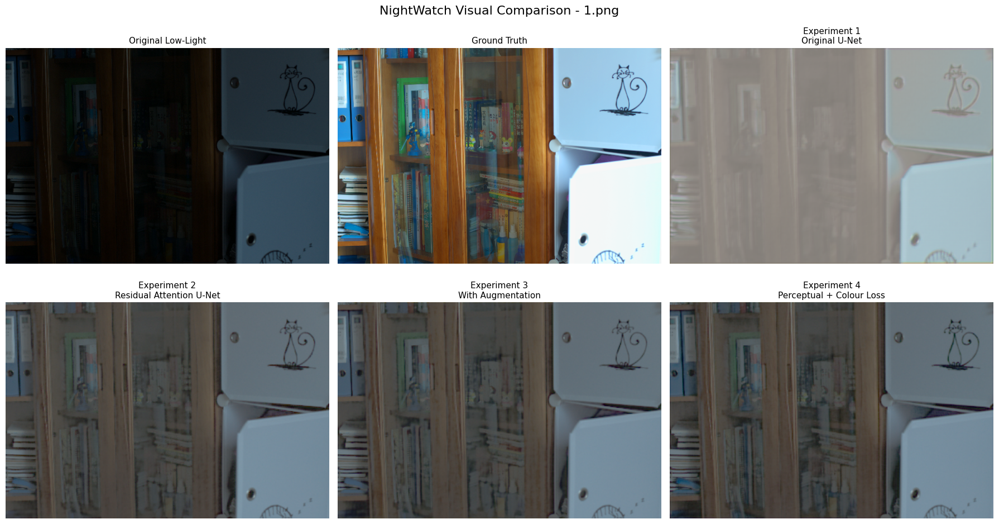

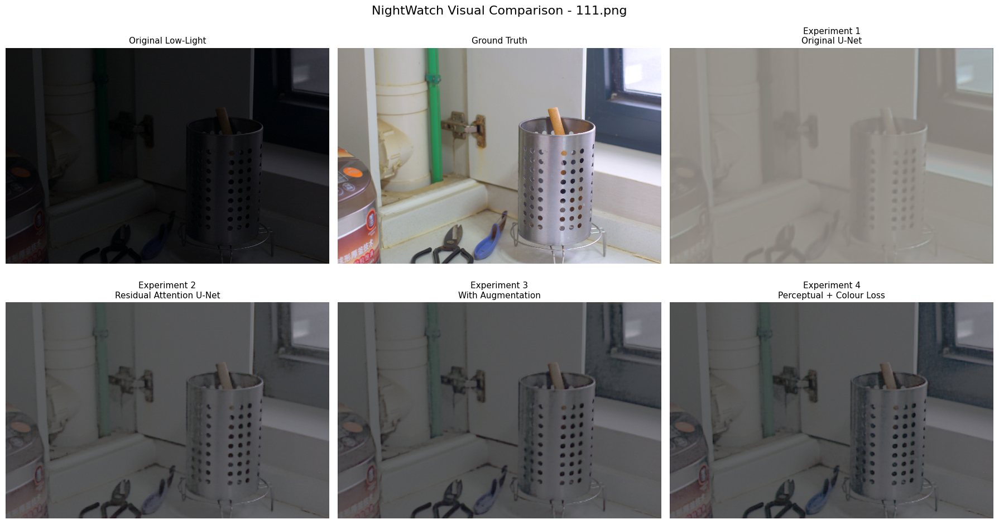

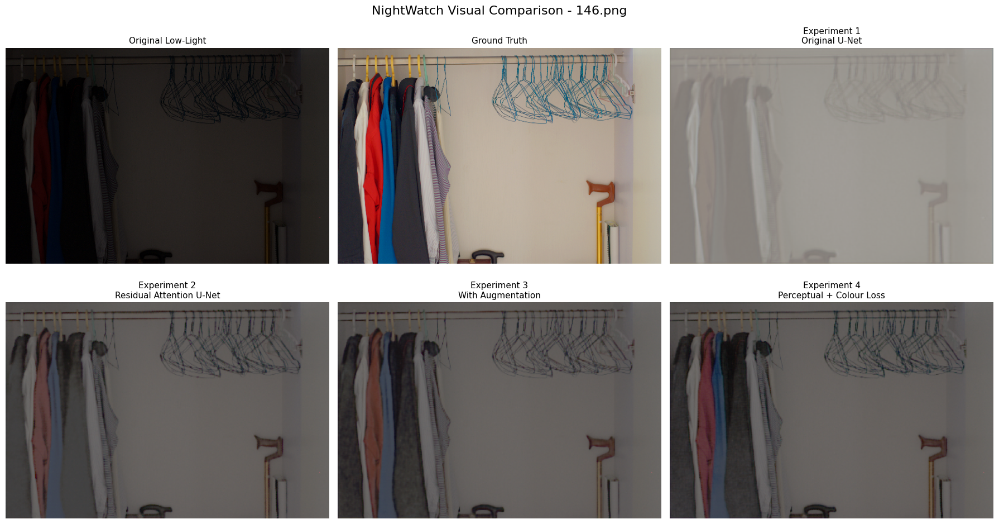

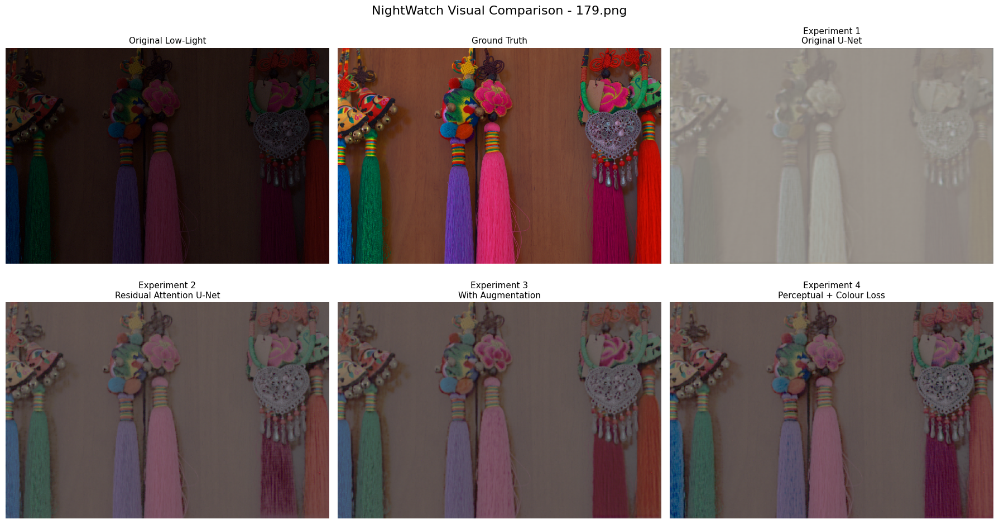

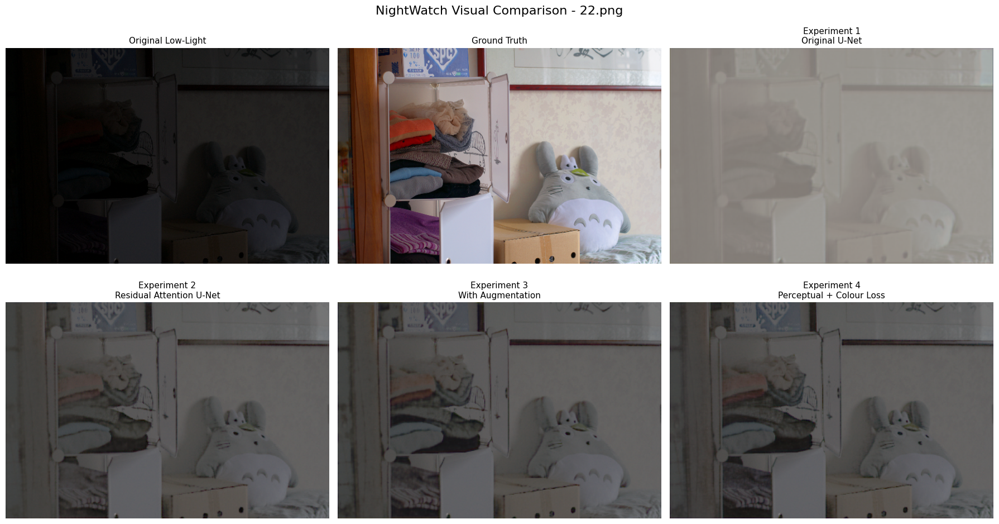

...

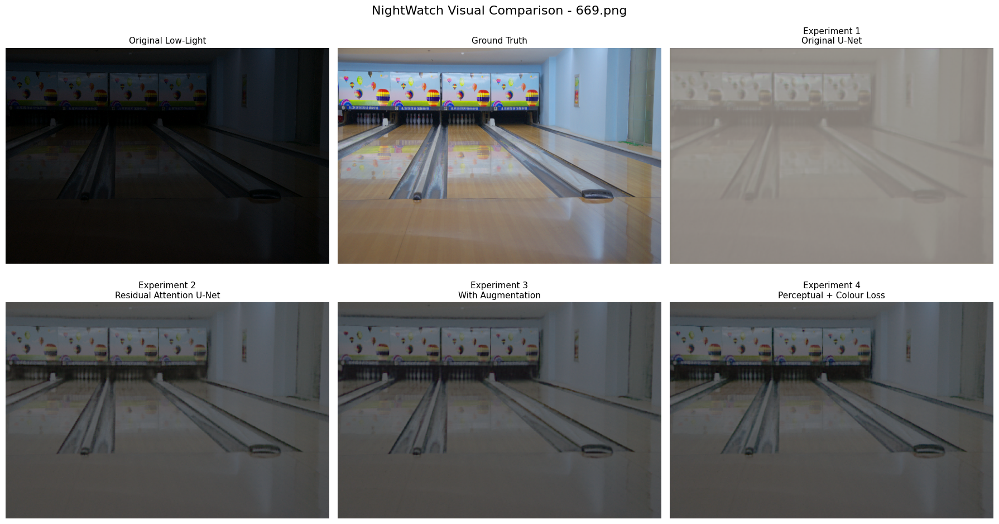

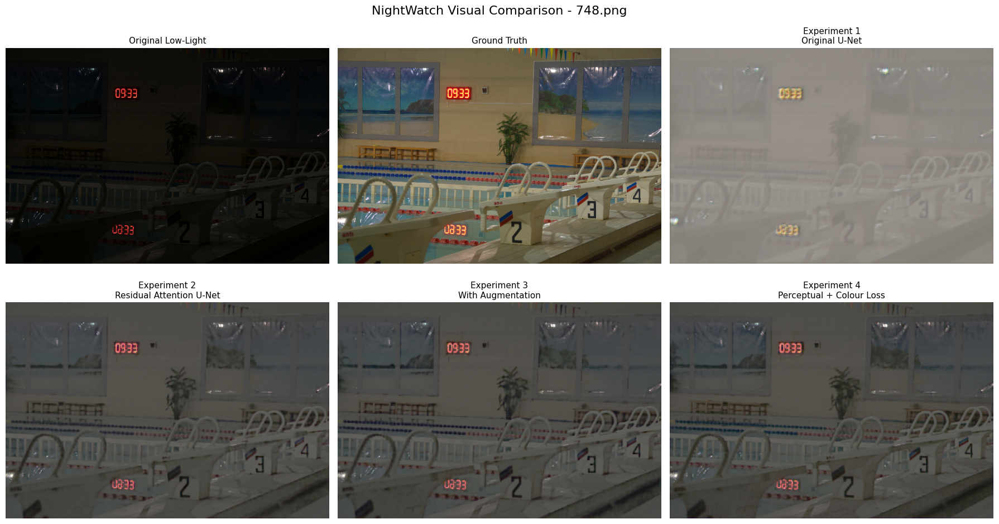

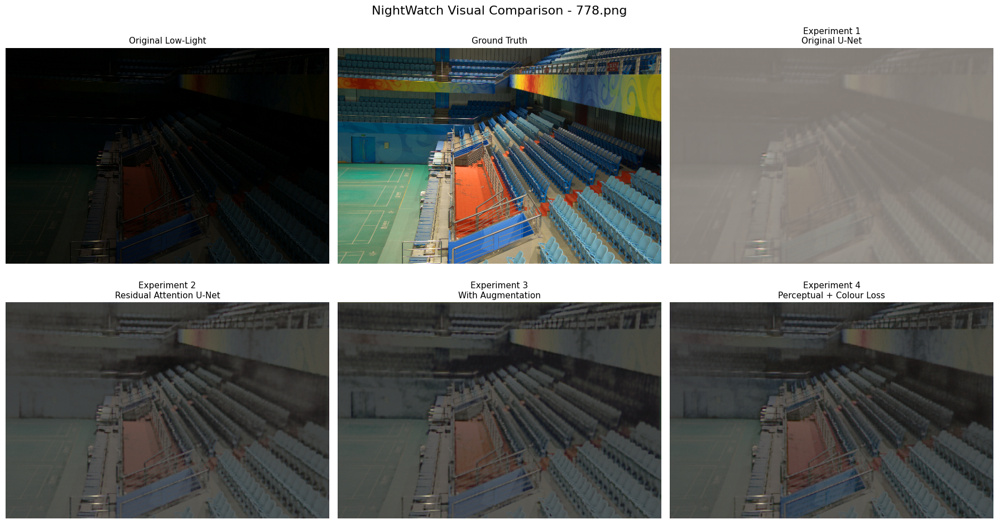

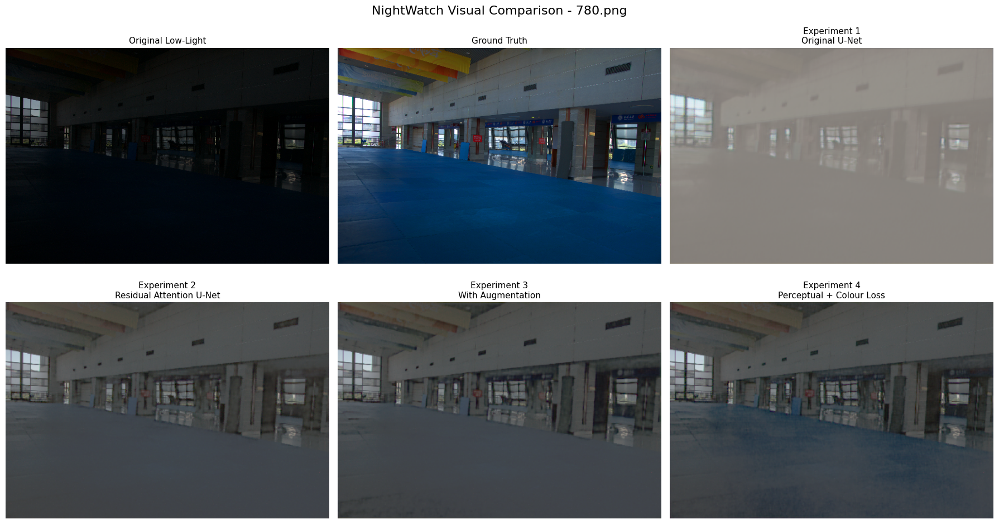

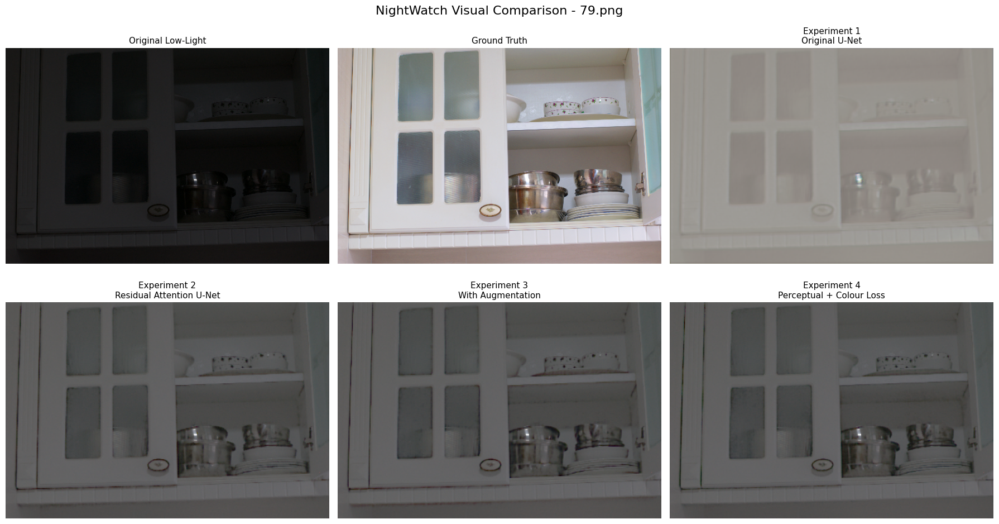


Visual comparisons saved at:
/content/NightWatch/results/visual_comparisons


In [65]:

import os
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import tensorflow as tf

BASE = Path("/content/NightWatch")

# Image folders
LOW_DIR = BASE / "dataset/LOL/lol_dataset/eval15/low"
HIGH_DIR = BASE / "dataset/LOL/lol_dataset/eval15/high"

RESULT_DIRS = {
    "Experiment 1\nOriginal U-Net":
        BASE / "results/eval15",

    "Experiment 2\nResidual Attention U-Net":
        BASE / "results/resunet_eval15",

    "Experiment 3\nWith Augmentation":
        BASE / "results/resunet_aug_eval15",

    "Experiment 4\nPerceptual + Colour Loss":
        BASE / "results/resunet_perceptual_eval15"
}

OUTPUT_DIR = BASE / "results/visual_comparisons"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Find evaluation images
extensions = {".png", ".jpg", ".jpeg"}
image_names = sorted(
    p.name for p in LOW_DIR.iterdir()
    if p.suffix.lower() in extensions
)

print("Total evaluation images:", len(image_names))


# Helper function to load an image
def load_image(path):
    img = Image.open(path).convert("RGB")
    return np.asarray(img)


# Helper function to locate enhanced image
def find_result(folder, image_name):
    # Exact filename first
    exact_path = folder / image_name
    if exact_path.exists():
        return exact_path

    # Try filename with common extensions
    stem = Path(image_name).stem
    for ext in extensions:
        candidate = folder / f"{stem}{ext}"
        if candidate.exists():
            return candidate

    return None


# Display comparisons
for image_name in image_names:

    low_path = LOW_DIR / image_name
    high_path = HIGH_DIR / image_name

    low_img = load_image(low_path)
    high_img = load_image(high_path)

    images = [
        ("Original Low-Light", low_img),
        ("Ground Truth", high_img)
    ]

    for exp_name, folder in RESULT_DIRS.items():

        result_path = find_result(folder, image_name)

        if result_path is not None:
            enhanced_img = load_image(result_path)
            images.append((exp_name, enhanced_img))
        else:
            print(f"Missing: {image_name} in {folder}")

    # Create figure
    fig, axes = plt.subplots(
        2, 3, figsize=(18, 10)
    )

    axes = axes.flatten()

    for ax, (title, img) in zip(axes, images):
        ax.imshow(img)
        ax.set_title(title, fontsize=11)
        ax.axis("off")

    # Hide unused axes
    for ax in axes[len(images):]:
        ax.axis("off")

    fig.suptitle(
        f"NightWatch Visual Comparison - {image_name}",
        fontsize=16
    )

    plt.tight_layout()

    # Save comparison
    save_path = OUTPUT_DIR / f"comparison_{image_name}"
    plt.savefig(save_path, dpi=150, bbox_inches="tight")

    plt.show()
    plt.close(fig)

print("\nVisual comparisons saved at:")
print(OUTPUT_DIR)


In [3]:

from pathlib import Path

BASE = Path("/content/NightWatch")

folders = [
    BASE / "dataset/LOL/lol_dataset/eval15/low",
    BASE / "dataset/LOL/lol_dataset/eval15/high",
    BASE / "results/eval15",
    BASE / "results/resunet_eval15",
    BASE / "results/resunet_aug_eval15",
    BASE / "results/resunet_perceptual_eval15"
]

for folder in folders:
    print("\nFolder:", folder)
    print("Exists:", folder.exists())

    if folder.exists():
        files = sorted(
            p.name for p in folder.iterdir()
            if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
        )
        print("Number of images:", len(files))
        print("First 10 files:", files[:10])



Folder: /content/NightWatch/dataset/LOL/lol_dataset/eval15/low
Exists: False

Folder: /content/NightWatch/dataset/LOL/lol_dataset/eval15/high
Exists: False

Folder: /content/NightWatch/results/eval15
Exists: False

Folder: /content/NightWatch/results/resunet_eval15
Exists: False

Folder: /content/NightWatch/results/resunet_aug_eval15
Exists: False

Folder: /content/NightWatch/results/resunet_perceptual_eval15
Exists: False


In [4]:

import os
from pathlib import Path

print("Current directory:", os.getcwd())
print("\nContent directory:")

for item in Path("/content").iterdir():
    print(" -", item.name)

print("\nChecking Google Drive:")

drive = Path("/content/drive/MyDrive")
print("Google Drive mounted:", drive.exists())

if drive.exists():
    print("Drive folders:")
    for item in list(drive.iterdir())[:20]:
        print(" -", item.name)


Current directory: /content

Content directory:
 - .config
 - sample_data

Checking Google Drive:
Google Drive mounted: False


In [5]:
Current directory: /content

Content directory:
 - .config
 - sample_data

Checking Google Drive:
Google Drive mounted: False

SyntaxError: invalid syntax (3842388996.py, line 1)

In [6]:

from google.colab import drive
drive.mount('/content/drive')


MessageError: Error: credential propagation was unsuccessful

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import colorsys

BASE = Path("/content/NightWatch")
name = "111.png"

paths = {
    "Original": BASE / "dataset/LOL/lol_dataset/eval15/low" / name,
    "Ground Truth": BASE / "dataset/LOL/lol_dataset/eval15/high" / name,
    "Experiment 2": BASE / "results/resunet_eval15" / name,
    "Experiment 3": BASE / "results/resunet_aug_eval15" / name,
    "Experiment 4": BASE / "results/resunet_perceptual_eval15" / name
}

def analyze_image(path):
    image = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0

    rgb_mean = image.mean(axis=(0, 1))
    brightness = image.mean()
    contrast = image.std()

    hsv = np.array([
        colorsys.rgb_to_hsv(*pixel)
        for pixel in image.reshape(-1, 3)
    ])

    saturation = hsv[:, 1].mean()

    return {
        "Red Mean": rgb_mean[0],
        "Green Mean": rgb_mean[1],
        "Blue Mean": rgb_mean[2],
        "Brightness": brightness,
        "Contrast": contrast,
        "Saturation": saturation
    }

rows = []

for label, path in paths.items():
    if not path.exists():
        print("Missing file:", path)
        continue

    metrics = analyze_image(path)
    metrics["Image"] = label
    rows.append(metrics)

df = pd.DataFrame(rows).set_index("Image")

print("IMAGE COLOUR AND CONTRAST ANALYSIS")
display(df.round(4))

# Compare RGB channel means
df[["Red Mean", "Green Mean", "Blue Mean"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("RGB Channel Comparison")
plt.ylabel("Mean pixel intensity")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Compare brightness, contrast and saturation
df[["Brightness", "Contrast", "Saturation"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Brightness, Contrast and Saturation")
plt.ylabel("Metric value")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


Missing file: /content/NightWatch/dataset/LOL/lol_dataset/eval15/low/111.png
Missing file: /content/NightWatch/dataset/LOL/lol_dataset/eval15/high/111.png
Missing file: /content/NightWatch/results/resunet_eval15/111.png
Missing file: /content/NightWatch/results/resunet_aug_eval15/111.png
Missing file: /content/NightWatch/results/resunet_perceptual_eval15/111.png


KeyError: "None of ['Image'] are in the columns"

In [7]:
import os

print("NightWatch exists:", os.path.exists("/content/NightWatch"))

if os.path.exists("/content/NightWatch"):
    print(os.listdir("/content/NightWatch"))

NightWatch exists: False


In [8]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful